Single allele groupped structue models.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
import logomaker
import sys
import seaborn as sns
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"


 1. Read data

In [2]:
DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
# DATA_PATH_BASE = 'D:/Google Drive/Work/ITMO/data' #windows
# DATA_PATH_BASE = '/home/denklewer/Data' #ubuntu

DATA_PATH = f'{DATA_PATH_BASE}/length_dependent_hmm/per_length_per_kfold_split/' # work laptop
TARGET_PATH_TO_RESULTS = "experiment_results/core_multiple_allele/" #!CHANGE for bwv!

In [4]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
# per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
# per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")

ALLELES

['HLA-B*07:02',
 'HLA-DRB1*15:01',
 'HLA-A*02:01',
 'HLA-DPA1*01:03/DPB1*04:01',
 'HLA-DRB1*03:01',
 'HLA-DPA1*02:02/DPB1*05:01',
 'HLA-DRB5*01:01',
 'HLA-A*03:01',
 'HLA-A*01:01',
 'HLA-A*24:02',
 'HLA-A*11:01',
 'HLA-DRB3*01:01',
 'HLA-DRB1*01:01',
 'HLA-DRB1*04:01',
 'HLA-B*27:05']

In [5]:
def make_logo_for_data(binders_array, name, ax=None):
    sns.set_theme(style="white")
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True, ax=ax)
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

# 2. Prepare data and weithgs for training
## 2.1 Merge alleles into combinations

In [6]:
# combination_size = len(ALLELES)
# ALLELES = sorted(['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'
#                   ])
# ALLELES = sorted([ 'HLA-A*03:01'])

# ALLELES = sorted(['HLA-DRB1*01:01', 'HLA-DPA1*01:03-DPB1*04:01'])

sorted(['HLA-DRB1*01:01','HLA-DRB1*04:01','HLA-DPA1*01:03/DPB1*04:01','HLA-DRB1*03:01','HLA-DRB1*15:01', 'HLA-DRB3*01:01',
 'HLA-DRB5*01:01'])

ALLELES = sorted(['HLA-A*03:01'])

combination_size = 1
TOTAL_SPLITS = 5
NUM_RUNS = 5
USE_WEIGHTS = True
TARGET_LENGTHS= [12, 13, 14, 15, 16, 17, 18]
TARGET_LENGTHS= [9]

# TARGET_LENGTHS= [15]
# TARGET_LENGTHS= [9]
check_peptides = False

In [7]:
per_allele_per_kfold_per_length_binders_train.keys()

dict_keys(['HLA-B*07:02', 'HLA-DRB1*15:01', 'HLA-A*02:01', 'HLA-DPA1*01:03/DPB1*04:01', 'HLA-DRB1*03:01', 'HLA-DPA1*02:02/DPB1*05:01', 'HLA-DRB5*01:01', 'HLA-A*03:01', 'HLA-A*01:01', 'HLA-A*24:02', 'HLA-A*11:01', 'HLA-DRB3*01:01', 'HLA-DRB1*01:01', 'HLA-DRB1*04:01', 'HLA-B*27:05'])

## Motif for train data

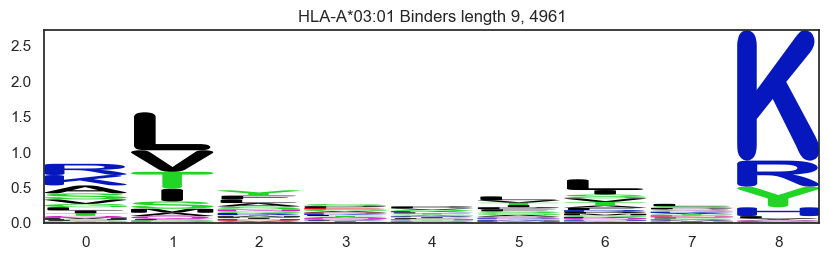

In [11]:
target_allele = ALLELES[0]
target_length = 9
peptides = per_allele_per_kfold_per_length_binders_train[target_allele][0][target_length]
make_logo_for_data(peptides, f"{ target_allele} Binders length {target_length}")

# Transform data

In [11]:
from data_reading_methods import merge_per_allele_sets_into_combination_sets

per_allele_per_kfold_per_length_binders_train_old = per_allele_per_kfold_per_length_binders_train
per_allele_per_kfold_per_length_binders_test_old = per_allele_per_kfold_per_length_binders_test


if check_peptides:
    transform_dicts=None

per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test = merge_per_allele_sets_into_combination_sets(
    per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test,
    combination_size=combination_size,
    selected_alelles=ALLELES,
    total_splits=TOTAL_SPLITS,
    list_of_transform_dicts=None
)
OLD_ALLELES = ALLELES
NEW_ALLELES = list(per_allele_per_kfold_per_length_binders_test.keys())
ALLELES = NEW_ALLELES

HLA-DPA1*01:03/DPB1*04:01+HLA-DRB1*01:01
Length 9: HLA-DPA1*01:03/DPB1*04:01 - 14 HLA-DRB1*01:01 - 109 
Length 10: HLA-DPA1*01:03/DPB1*04:01 - 68 HLA-DRB1*01:01 - 121 
Length 11: HLA-DPA1*01:03/DPB1*04:01 - 288 HLA-DRB1*01:01 - 165 
Length 12: HLA-DPA1*01:03/DPB1*04:01 - 730 HLA-DRB1*01:01 - 354 
Length 13: HLA-DPA1*01:03/DPB1*04:01 - 1380 HLA-DRB1*01:01 - 812 
Length 14: HLA-DPA1*01:03/DPB1*04:01 - 1820 HLA-DRB1*01:01 - 1248 
Length 15: HLA-DPA1*01:03/DPB1*04:01 - 1991 HLA-DRB1*01:01 - 5315 
Length 16: HLA-DPA1*01:03/DPB1*04:01 - 1596 HLA-DRB1*01:01 - 1433 
Length 17: HLA-DPA1*01:03/DPB1*04:01 - 1164 HLA-DRB1*01:01 - 981 
Length 18: HLA-DPA1*01:03/DPB1*04:01 - 760 HLA-DRB1*01:01 - 651 
Length 19: HLA-DPA1*01:03/DPB1*04:01 - 463 HLA-DRB1*01:01 - 305 
Length 20: HLA-DPA1*01:03/DPB1*04:01 - 301 HLA-DRB1*01:01 - 396 
Length 21: HLA-DPA1*01:03/DPB1*04:01 - 165 HLA-DRB1*01:01 - 157 
Length 22: HLA-DPA1*01:03/DPB1*04:01 - 111 HLA-DRB1*01:01 - 76 
Length 23: HLA-DPA1*01:03/DPB1*04:01 - 76 HLA

In [12]:
ALLELES

['HLA-DPA1*01:03/DPB1*04:01+HLA-DRB1*01:01']

## 2.2 Calculate counts of initial data (will be used to calculate weights further)

In [13]:
from data_reading_methods import extract_count_df, calculate_weights_based_on_length_counts

count_df_train = extract_count_df(per_allele_per_kfold_per_length_binders_train_old,
                                  selected_alleles=OLD_ALLELES,
                                  total_splits=TOTAL_SPLITS)
count_df_test = extract_count_df(per_allele_per_kfold_per_length_binders_test_old,
                                 selected_alleles=OLD_ALLELES,
                                 total_splits=TOTAL_SPLITS)


In [14]:
count_df_train.index.levels

FrozenList([['HLA-DPA1*01:03/DPB1*04:01', 'HLA-DRB1*01:01'], [0, 1, 2, 3, 4], [9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 30]])

## 2.3 Weights for data based on counts

In [15]:
per_allele_per_kfold_per_length_weights = calculate_weights_based_on_length_counts(count_df_train,
                                                                                   selected_alleles=ALLELES,
                                                                                   total_splits=TOTAL_SPLITS,
                                                                                   selected_lengths=TARGET_LENGTHS,
                                                                                   use_weights=USE_WEIGHTS)

Total data length for split 0 is 20235
Weights for lentgh 12 are {'HLA-DPA1*01:03/DPB1*04:01': 27.71917808219178, 'HLA-DRB1*01:01': 57.16101694915254}
Weights for lentgh 13 are {'HLA-DPA1*01:03/DPB1*04:01': 14.66304347826087, 'HLA-DRB1*01:01': 24.919950738916256}
Weights for lentgh 14 are {'HLA-DPA1*01:03/DPB1*04:01': 11.118131868131869, 'HLA-DRB1*01:01': 16.213942307692307}
Weights for lentgh 15 are {'HLA-DPA1*01:03/DPB1*04:01': 10.163234555499749, 'HLA-DRB1*01:01': 3.8071495766698025}
Weights for lentgh 16 are {'HLA-DPA1*01:03/DPB1*04:01': 12.678571428571429, 'HLA-DRB1*01:01': 14.12072575017446}
Weights for lentgh 17 are {'HLA-DPA1*01:03/DPB1*04:01': 17.3840206185567, 'HLA-DRB1*01:01': 20.62691131498471}
Weights for lentgh 18 are {'HLA-DPA1*01:03/DPB1*04:01': 26.625, 'HLA-DRB1*01:01': 31.08294930875576}
Total data length for split 1 is 20235
Weights for lentgh 12 are {'HLA-DPA1*01:03/DPB1*04:01': 27.71917808219178, 'HLA-DRB1*01:01': 57.16101694915254}
Weights for lentgh 13 are {'HLA-

## Transform to properties

# 2. Train HMMS
## 2.1 Code for HMM
### 2.1.1 Training code

In [16]:
from hmm_logic_methods import train_model, save_model, add_more_states_and_reset_transitions, init_grouped_structure_model_joiners_and_cycles



## 2.2 Train
### 2.2.1 Define treshold

In [17]:
stop_threshold = 0
cutoff = 0.00005
per_symbol_portion = -5
for target_length in TARGET_LENGTHS:
    target_length_for_training = target_length
    train_size = len(per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length])
    ## Stop threshold Hardcoded here
    stop_threshold +=  abs(cutoff * train_size * per_symbol_portion  * target_length_for_training)
stop_threshold = stop_threshold / len(TARGET_LENGTHS)
stop_threshold

10.870464285714288

### 2.2.2 Prepare  initial grouped structure models

In [18]:
# Training params
algorithm = 'viterbi'

params = dict()


# params['st'] = 7
# params['multiple_check_input'] = False
# params['alg'] = algorithm
# params['min_iters'] = 30
# params['max_iters'] = 65
# params['stop_threshold'] = stop_threshold
# params['emission_pseudocount'] = 1
# params['transition_pseudocount'] = 0
# params['verbose'] = True
# params['lr_decay'] = 0
# params['edge_inertia'] = 0.25
# params['distribution_inertia'] = 0
# params['groups'] = 7
# params['states_per_group'] = 1
# params['use_pseudocount'] = True

params['st'] = 35
params['multiple_check_input'] = False
params['alg'] = algorithm
params['min_iters'] = 30
params['max_iters'] = 65
params['stop_threshold'] = stop_threshold
params['emission_pseudocount'] = 1
params['transition_pseudocount'] = 1
params['verbose'] = True
params['lr_decay'] = 0
params['edge_inertia'] = 0
params['distribution_inertia'] = 0
params['groups'] = 7
params['states_per_group'] = 5
params['use_pseudocount'] = False
# Class 1 params
params['self_cycle'] = False
params['start_cycle'] = True
params['end_cycle'] = True

params['freeze_distr'] = False # wether to freeze start and end cycle distributions
params['cycle_pseudocount'] = 1



assert params['st'] % params['groups'] == 0
assert params['st'] % params['states_per_group'] == 0
assert params['st'] == params['groups'] *  params['states_per_group']

params_for_string = {key: value for key, value in params.items() if key in ['st', 'alg', 'min_iters']}
params_string = "-".join([f"{value}-{key}" for key, value in params_for_string.items()])
lengths_string = "-".join(map(str, TARGET_LENGTHS))

initial_params = None

In [19]:
from pomegranate import *
import json
import numpy as np
import pandas as pd
from pomegranate.io import BatchedDataGenerator, SequenceGenerator
from hmm_visualization_methods import convert_graph_to_good_format
import networkx as nx
from tqdm import tqdm
from collections import defaultdict
from pomegranate import IndependentComponentsDistribution

MINUS_INF_CONSTANT = -20
MINUS_INF_CONSTANT_NORMALIZED = -0.5

def init_distribution(amino_acids=None, initial_means=None, initial_stds=None, discrete_distribution=False):
    amino_acids_list = list(amino_acids)
    if not discrete_distribution:
        components_d  = list()
        for i in range(len(initial_means)):
            mean_value = initial_means[i]
            std_value = initial_stds[i]
            d = NormalDistribution(mean_value, std_value)
            components_d.append(d)
        total_d = IndependentComponentsDistribution(components_d)
    else:
        d_dict = {key: prob for key, prob in zip(amino_acids_list, np.random.default_rng().uniform(0, 1, size=len(amino_acids_list)))}
        d_sum = sum(d_dict.values())
        d_dict = {key: value/d_sum for key, value in d_dict.items()}
        total_d = DiscreteDistribution(d_dict)
    return total_d


def init_grouped_structure_model_joiners_and_cycles_here(
        states_per_group=5, # may be int or list of numbers for each group
        number_of_groups=5,
        amino_acids="ACDEFGHIKLMNPQRSTVWY",
        freeze_distr=False,
        CYCLE_PSEUDOCOUNT=1,
        initial_params=None,
        start_cycle=True,
        end_cycle=True,
        self_cycles=False,
        discrete_distribution=False
):

    INTRAGROUP_WEIGHT = 1
    INTERGROUP_WEIGHT = 1


    START_WEIGHT = 1
    TO_FIRST_CYCLE_WEIGHT = 5
    TO_LAST_CYCLE_WEIGHT = 5


    if start_cycle or end_cycle:
        TO_FIRST_JOINER_WEIGHT = 5#just to make transitions even inside groups
        TO_LAST_JOINER_WEIGHT = 2.5
    else:
        TO_FIRST_JOINER_WEIGHT = 1
        TO_LAST_JOINER_WEIGHT = 2.5

    IN_FIRST_CYCLE_WEIGHT = TO_FIRST_JOINER_WEIGHT
    IN_LAST_CYCLE_WEIGHT = 1
    END_WEIGHT = 1
    FROM_LAST_CYCLE_WEIGHT = 1
    amino_acids_list = list(amino_acids)


    joiner_positions = {0: [i for i in range(combination_size)], 1: [i for i in range(combination_size, combination_size*2)]}
    number_of_joiners = sum(len(positions) for positions in joiner_positions.values())
    number_of_groups = number_of_groups

    if type(states_per_group) == list:
        assert number_of_groups == len(states_per_group), f"Number of groups is expected to be {number_of_groups} but got {len(states_per_group)} in a list of states per group"
    else:
        states_per_group = [states_per_group for i in range(number_of_groups)]
    distributions = list()


    mean_values = list()
    stds = list()
    if initial_params:
        for initial_distr_params in initial_params:
            mean_values.append(initial_distr_params['mean'])
            stds.append(initial_distr_params['std'])
        print(f"mean values : {mean_values}")
        print(f"std values : {stds}")

    # initialize group states
    for group_number in range(number_of_groups):
        states_in_group = states_per_group[group_number]
        for state_num in range(states_in_group):
            total_d = init_distribution(amino_acids=amino_acids,
                                        initial_means=mean_values,
                                        initial_stds=stds,
                                        discrete_distribution=discrete_distribution)
            distributions.append(total_d)
    #initialize joiner states (random here)
    joiner_label_to_index_in_model = dict()
    for joiner_name in range(number_of_joiners):
        # d = DiscreteDistribution(
        #     {key: prob for key, prob in zip(amino_acids_list, np.random.uniform(0, 1, size=len(amino_acids_list)))})
        total_d = init_distribution(amino_acids=amino_acids,
                                    initial_means=mean_values,
                                    initial_stds=stds,
                                    discrete_distribution=discrete_distribution)
        joiner_label_to_index_in_model[joiner_name] = len(distributions)
        distributions.append(total_d)
    # initialize cycle states
    number_of_cycles = 0
    cycle_label_to_index_in_model = dict()

    if start_cycle:
        # for each joiner its own cycle
        for start_cycle_name in (joiner_positions[0]):
            start_d = init_distribution(amino_acids=amino_acids,
                                        initial_means=mean_values,
                                        initial_stds=stds,
                                        discrete_distribution=discrete_distribution)

            if freeze_distr:
                start_d.freeze()

            cycle_label_to_index_in_model[start_cycle_name] = len(distributions)
            distributions.append(start_d)
            number_of_cycles += 1
    if end_cycle:
        for end_cycle_name in joiner_positions[max(joiner_positions.keys())]:

            end_d = init_distribution(amino_acids=amino_acids,
                                  initial_means=mean_values,
                                    initial_stds=stds,
                                    discrete_distribution=discrete_distribution)
            if freeze_distr:
                end_d.freeze()

            cycle_label_to_index_in_model[end_cycle_name] = len(distributions)
            distributions.append(end_d)
            number_of_cycles += 1



    # print("joiners positions", joiner_label_to_index_in_model)

    num_states = sum(states_per_group) + number_of_joiners +  number_of_cycles # groups, joiners, 2 cycles
    assert num_states == len(distributions)
    print(f"states will be groups:{sum(states_per_group)} + joiners:{number_of_joiners} + start/end cycles:{ number_of_cycles}")

    state_names = ["s{:03d}".format(i) for i in range(num_states)]
    transition_matrix = numpy.zeros((num_states, num_states))

    # start probabilities
    first_joiners = set(joiner_label_to_index_in_model[label] for label in joiner_positions[0])
    last_joiners = set(joiner_label_to_index_in_model[label] for label in joiner_positions[max(joiner_positions.keys())])
    # connect start cycle to the first joiners

    start_cycles = set(cycle_label_to_index_in_model[label] for label in joiner_positions[0]) # because each joiner has it's own cycle
    end_cycles = set(cycle_label_to_index_in_model[label] for label in joiner_positions[max(joiner_positions.keys())]) # because each joiner has it's own cycle



    # start only for first cycle and first joiner
    start_probabilities = [START_WEIGHT
                           if i in start_cycles or i in first_joiners
                           else 0
                           for i in range(num_states)]


    # do not restrict ending in multiple states, so probs are equal to transitions inside

    end_probabilities = [END_WEIGHT
                         if i in end_cycles or i in last_joiners
                         else 0
                         for i in range(num_states)]

    #  start cycle transitions
    if start_cycle:
        for start_cycle_idx, joiner_idx in zip(start_cycles, first_joiners):
            transition_matrix[start_cycle_idx][joiner_idx] = TO_FIRST_JOINER_WEIGHT # from cycle to joiners
            # for joiner_idx in first_joiners:
            #     transition_matrix[start_cycle_idx][joiner_idx] = TO_FIRST_JOINER_WEIGHT # from cycle to joiners
            transition_matrix[start_cycle_idx][start_cycle_idx] = IN_FIRST_CYCLE_WEIGHT #cycle
            start_probabilities[start_cycle_idx] = TO_FIRST_CYCLE_WEIGHT #from start to cycle

    # connect last joiners to last cycle
    if end_cycle:
        for end_cycle_idx, joiner_idx in zip(end_cycles, last_joiners):
            transition_matrix[joiner_idx][end_cycle_idx] = TO_LAST_CYCLE_WEIGHT
            # for joiner_idx in last_joiners:
            #     transition_matrix[joiner_idx][end_cycle_idx] = TO_LAST_CYCLE_WEIGHT
            transition_matrix[end_cycle_idx][end_cycle_idx] = IN_LAST_CYCLE_WEIGHT


    # Transitions inside groups
    for group_number in range(number_of_groups):
        states_in_group = states_per_group[group_number]
        for i in range(states_in_group):
            state_num_from = sum(states_per_group[:group_number]) + i
            # fill transitions inside each group with INTRAGROUP_WEIGHT
            for j in range(states_in_group):

                state_num_to =  sum(states_per_group[:group_number]) + j
                if state_num_from != state_num_to:
                    transition_matrix[state_num_from][state_num_to] = INTRAGROUP_WEIGHT
            if self_cycles:
                transition_matrix[state_num_from][state_num_from] = INTRAGROUP_WEIGHT
            # transition to next group
            if group_number != number_of_groups - 1:
                for j in range(states_in_group):
                    state_num_to = sum(states_per_group[:group_number+1]) + j
                    transition_matrix[state_num_from][state_num_to] = INTERGROUP_WEIGHT



    # connect first joiner to first group
    for joiner_index in first_joiners:
        group_number = 0
        state_num_from = joiner_index
        states_in_group =  states_per_group[group_number]
        for j in range(states_in_group):
            state_num_to = sum(states_per_group[:group_number]) + j
            transition_matrix[state_num_from][state_num_to] = INTERGROUP_WEIGHT

    # connect last group to the last joiner
    for joiner_index in last_joiners:
        group_number = number_of_groups -1
        state_num_to = joiner_index
        states_in_group =  states_per_group[group_number]
        for j in range(states_in_group):
            state_num_from = sum(states_per_group[:group_number]) + j
            transition_matrix[state_num_from][state_num_to] = TO_LAST_JOINER_WEIGHT
    model_name = 'grouped_model'


    # assert sum(start_probabilities) == len(joiner_positions[0])* START_WEIGHT + TO_CYCLE_WEIGHT, start_probabilities
    # assert sum(end_probabilities) ==  (len(joiner_positions[max(joiner_positions.keys())]) + 1)  * END_WEIGHT, end_probabilities + list(last_joiners)

    model = HiddenMarkovModel.from_matrix(
        name=model_name,
        transition_probabilities=transition_matrix,
        starts=start_probabilities,
        distributions=distributions,
        ends=end_probabilities,
        state_names=state_names,
        verbose=True)
    # Update created model with specific pseudocounts
    if start_cycle:
        for start_cycle_idx, joiner_idx in zip(start_cycles, first_joiners):
            model.add_transition(model.states[start_cycle_idx], model.states[start_cycle_idx], IN_FIRST_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
            model.add_transition(model.start, model.states[start_cycle_idx], TO_FIRST_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
            model.add_transition(model.states[start_cycle_idx], model.states[joiner_idx], TO_FIRST_JOINER_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
        #
        # for joiner_idx in first_joiners:
        #         model.add_transition(model.states[start_cycle_idx], model.states[joiner_idx], TO_FIRST_JOINER_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
    if end_cycle:
        for end_cycle_idx, joiner_idx in zip(end_cycles, last_joiners):
            model.add_transition(model.states[end_cycle_idx], model.states[end_cycle_idx], IN_LAST_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
            model.add_transition(model.states[end_cycle_idx],model.end, FROM_LAST_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
            model.add_transition(model.states[joiner_idx], model.states[end_cycle_idx], TO_LAST_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
            # for joiner_idx in last_joiners:
            #     model.add_transition(model.states[joiner_idx], model.states[end_cycle_idx], TO_LAST_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)


        # model.add_transition(model.states[end_cycle_idx], model.states[end_cycle_idx], IN_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)

    model.bake(verbose=True)
    return model

In [20]:
prepared_model = init_grouped_structure_model_joiners_and_cycles_here(
    states_per_group=int(params['states_per_group']),
    number_of_groups=params['groups'],
    CYCLE_PSEUDOCOUNT=params['cycle_pseudocount'],
    freeze_distr=params['freeze_distr'],
    initial_params=initial_params,
    start_cycle=params['start_cycle'],
    end_cycle=params['end_cycle'],
    self_cycles=params['self_cycle'],
    discrete_distribution=check_peptides
)

states will be groups:35 + joiners:4 + start/end cycles:4
grouped_model : grouped_model-start summed to 12.0, normalized to 1.0
grouped_model : s000 summed to 9.0, normalized to 1.0
grouped_model : s001 summed to 9.0, normalized to 1.0
grouped_model : s002 summed to 9.0, normalized to 1.0
grouped_model : s003 summed to 9.0, normalized to 1.0
grouped_model : s004 summed to 9.0, normalized to 1.0
grouped_model : s005 summed to 9.0, normalized to 1.0
grouped_model : s006 summed to 9.0, normalized to 1.0
grouped_model : s007 summed to 9.0, normalized to 1.0
grouped_model : s008 summed to 9.0, normalized to 1.0
grouped_model : s009 summed to 9.0, normalized to 1.0
grouped_model : s010 summed to 9.0, normalized to 1.0
grouped_model : s011 summed to 9.0, normalized to 1.0
grouped_model : s012 summed to 9.0, normalized to 1.0
grouped_model : s013 summed to 9.0, normalized to 1.0
grouped_model : s014 summed to 9.0, normalized to 1.0
grouped_model : s015 summed to 9.0, normalized to 1.0
grouped_

In [21]:
with open('model.png', 'w+') as f:
    prepared_model.plot(file=f, crop_zero=True, rotation=90, rotate=90)

In [22]:
from hmm_visualization_methods import *
plot_distributions_for_states(prepared_model,"test/", horizontal=False, discrete=check_peptides, initial_params=initial_params)

In [23]:
make_pyviz_graph(prepared_model, "test/", precision=3)

Converting graph for model (grouped_model) (Delete zero edges)


<class 'pyvis.network.Network'> |N|=45 |E|=326

In [24]:
# allele_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])
# ten_mer = allele_peptides[12]
# print(ten_mer, len(ten_mer))
#prob, path = model.viterbi(ten_mer)
#print([item[0] for item in path])
# sixteen_mer = peptide_properties[8900]
# print(sixteen_mer, len(sixteen_mer))

In [25]:
#pd.DataFrame(model.forward(sixteen_mer))

In [26]:
#pd.DataFrame(model.forward_backward(sixteen_mer)[1])

In [27]:
#pd.DataFrame(model.forward_backward(ten_mer)[1])

In [28]:
#ten_mer

In [29]:
#state_sums = [sum(state.distribution.parameters[0].values()) for state in model.states[:-2]]
# assert np.isclose(sum(state_sums), len(state_sums))

## Prepare models

In [30]:
per_allele_per_run_per_split_prepared_models = dict()
for allele_name in ALLELES:
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_').replace('/', '_')
    per_allele_per_run_per_split_prepared_models[allele_name] = dict()
    for run_num in range(NUM_RUNS):
        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = dict()
        for split_num in range(TOTAL_SPLITS):
            # prepared_model  = init_grouped_structure_model(states_per_group=int(params['st']/params['groups']), number_of_groups=params['groups'])
            prepared_model = init_grouped_structure_model_joiners_and_cycles_here(
                states_per_group=int(params['states_per_group']),
                number_of_groups=params['groups'],
                CYCLE_PSEUDOCOUNT=params['cycle_pseudocount'],
                freeze_distr=params['freeze_distr'],
                initial_params=initial_params,
                start_cycle=params['start_cycle'],
                end_cycle=params['end_cycle'],
                self_cycles=params['self_cycle'],
                discrete_distribution=check_peptides
            )


            prepared_model.name = f'{run_num}_run-{lengths_string}-{params_string}_model-{target_allele_name}-{split_num}'
            per_allele_per_run_per_split_prepared_models[allele_name][run_num][split_num] = prepared_model

states will be groups:35 + joiners:4 + start/end cycles:4
grouped_model : grouped_model-start summed to 12.0, normalized to 1.0
grouped_model : s000 summed to 9.0, normalized to 1.0
grouped_model : s001 summed to 9.0, normalized to 1.0
grouped_model : s002 summed to 9.0, normalized to 1.0
grouped_model : s003 summed to 9.0, normalized to 1.0
grouped_model : s004 summed to 9.0, normalized to 1.0
grouped_model : s005 summed to 9.0, normalized to 1.0
grouped_model : s006 summed to 9.0, normalized to 1.0
grouped_model : s007 summed to 9.0, normalized to 1.0
grouped_model : s008 summed to 9.0, normalized to 1.0
grouped_model : s009 summed to 9.0, normalized to 1.0
grouped_model : s010 summed to 9.0, normalized to 1.0
grouped_model : s011 summed to 9.0, normalized to 1.0
grouped_model : s012 summed to 9.0, normalized to 1.0
grouped_model : s013 summed to 9.0, normalized to 1.0
grouped_model : s014 summed to 9.0, normalized to 1.0
grouped_model : s015 summed to 9.0, normalized to 1.0
grouped_

In [31]:
# cycle_state = prepared_model.states[27]
# start = prepared_model.states[29]
# prepared_model.graph.edges()[cycle_state, cycle_state]

## Do training

In [32]:
%%time

per_name_models = dict()
per_allele_per_run_per_split_new_histories = dict()
for allele_name in ALLELES:
    per_allele_per_run_per_split_new_histories[allele_name] = dict()
    for run_num in range(NUM_RUNS):
        print(f"run {run_num}")
        per_kfold_per_length_data = per_allele_per_kfold_per_length_binders_train[allele_name]
        per_kfold_per_length_weights = per_allele_per_kfold_per_length_weights[allele_name]


        models, histories = train_model(allele_name=allele_name,
                                        per_kfold_per_length_data=per_kfold_per_length_data,
                                        per_kfold_per_length_weights_for_data=per_kfold_per_length_weights,
                                        target_lengths=TARGET_LENGTHS,
                                        multiple_check_input=params['multiple_check_input'],
                                        algorithm=params['alg'],
                                        verbose=params['verbose'],
                                        per_kfold_per_length_test_data=per_allele_per_kfold_per_length_binders_test[allele_name],
                                        stop_threshold=params['stop_threshold'],
                                        min_iterations= params['min_iters'],
                                        max_iterations=params['max_iters'],
                                        prepared_models=per_allele_per_run_per_split_prepared_models[allele_name][run_num],
                                        emission_pseudocount=params['emission_pseudocount'],
                                        transition_pseudocount=params['transition_pseudocount'],
                                        edge_inertia=params['edge_inertia'],
                                        distribution_inertia=params['distribution_inertia'],
                                        lr_decay=params['lr_decay'],
                                        use_pseudocount=params['use_pseudocount'])

        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = models
        per_allele_per_run_per_split_new_histories[allele_name][run_num] = histories
        # per_allele_per_run_per_split_models[allele_name][run_num] = models
        for split_num, model in models.items():
            per_name_models[model.name] = model
        # save models
        for split_num, model in models.items():
            history = histories[split_num]
            save_model(TARGET_PATH_TO_RESULTS, model,history)



run 0
split 0
train size 20235
Shuffling for fairness 
Simple training: Train Length 20235, init_batch_size None
Use pseudocount is False
[1] Improvement: 52382.72770483908	Time (s): 3.524
[2] Improvement: 3226.6187031358713	Time (s): 3.333
[3] Improvement: 2130.564234061283	Time (s): 3.413
[4] Improvement: 2028.6968677452533	Time (s): 3.411
[5] Improvement: 2275.893765154644	Time (s): 3.272
[6] Improvement: 2592.8974963881774	Time (s): 3.394
[7] Improvement: 2523.2581423600204	Time (s): 3.297
[8] Improvement: 1651.8819401585497	Time (s): 3.376
[9] Improvement: 967.8082725859713	Time (s): 3.393
[10] Improvement: 367.5325906275539	Time (s): 3.994
[11] Improvement: 107.79273162875324	Time (s): 4.131
[12] Improvement: -10.207239745999686	Time (s): 4.42
[13] Improvement: 27.14632299391087	Time (s): 5.21
[14] Improvement: 72.64687587635126	Time (s): 6.287
[15] Improvement: 38.29777825821657	Time (s): 4.001
[16] Improvement: 2.852581786457449	Time (s): 4.389
[17] Improvement: 5.1757487591821

In [33]:
from hmm_visualization_methods import *

In [34]:
%%time

for i, model in enumerate(per_name_models.values()):
    print(i)
    # with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph.png", 'w+') as f:
    #     model.plot(file=f, crop_zero=False)
    with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph_cropped.png", 'w+') as f:
        model.plot(file=f, crop_zero=True)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
CPU times: total: 234 ms
Wall time: 5.32 s


In [35]:
%%time

for i, model in enumerate(per_name_models.values()):
    plot_distributions_for_states(model,TARGET_PATH_TO_RESULTS, horizontal=False, discrete=check_peptides, initial_params=initial_params)
    print(i)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
CPU times: total: 2min 57s
Wall time: 2min 59s


In [36]:
from hmm_visualization_methods import *


per_name_pyviz = dict()
for name, model in per_name_models.items():
    per_name_pyviz[name] = make_pyviz_graph(model, TARGET_PATH_TO_RESULTS, precision=3)

Converting graph for model (0_run-12-13-14-15-16-17-18-35-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0) (Delete zero edges)
new starting point
Converting graph for model (1_run-12-13-14-15-16-17-18-35-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0) (Delete zero edges)
Converting graph for model (2_run-12-13-14-15-16-17-18-35-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0) (Delete zero edges)
Converting graph for model (3_run-12-13-14-15-16-17-18-35-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0) (Delete zero edges)
Converting graph for model (4_run-12-13-14-15-16-17-18-35-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0) (Delete zero edges)
Converting graph for model (5_run-12-13-14-15-16-17-18-35-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0) (Delete zero edges)
Converting graph for model (6_run-12-13-14-15